3. سوالات تکلیف

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import pandas as pd


sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data

3-3 نرمال سازی دسته ای و لایه ای، مقدار دهی اولیه (روی mnist)

3-3-1 ﻣﻘﺎﻳﺴﻪ ﻱ ﻣﻘﺪﺍﺭﺩﻫﻲ ﺍﻭﻟﻴﻪ: ﻳﻚ MLP ﺑﺎ ۳ ﻻﻳﻪ ﻣﺨﻔﻲ (ﻫﺮ ﻛﺪﺍﻡ ۲۵۶ ﻧﺮﻭﻥ) ﺭﻭﻱ MNIST (10 ﻛﻼﺱ) ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ. ﻣﻘﺪﺍﺭﺩﻫﻲ ﺍﻭﻟﻴﻪ ﺭﺍ ﺑﻪ ﭼﻬﺎﺭ ﺭﻭﺵ He ،Xavier ،Zero، ﻭ Random Normal (ﺑﺎ ﻣﻴﺎﻧﮕﻴﻦ 0 ﻭ ﺍﻧﺤﺮﺍﻑ 0.01) ﺗﻨﻈﻴﻢ ﻛﻨﻴﺪ.

الف) ﻛﺪﺍﻡ ﻣﻘﺪﺍﺭﺩﻫﻲ ﺳﺮﻳﻊ ﺗﺮﻳﻦ ﻫﻤﮕﺮﺍﻳﻲ ﺭﺍ ﺩﺍﺭﺩ؟ ﻧﻤﻮﺩﺍﺭ ﺩﻗﺖ ﺁﺯﻣﻮﻥ ﺑﺮ ﺣﺴﺐ ﺩﻭﺭﻩ ﺭﺍ ﺑﺮﺍﻱ ﻫﺮ ﺭﻭﺵ ﺭﺳﻢ ﻛﻨﻴﺪ.

ب) دﺭ ﺭﻭﺵ Zero ﭼﻪ ﺍﺗﻔﺎﻗﻲ ﻣﻲ ﺍﻓﺘﺪ؟ ﺗﻮﺿﻴﺢ ﺩﻫﻴﺪ .

In [2]:
class ThreeLayerMLP(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, hidden_dim)
        self.fc4 = nn.Linear(hidden_dim, num_classes)
        self.relu = nn.ReLU()
        # ذخیره لایه‌ها برای مقداردهی
        self.layers = [self.fc1, self.fc2, self.fc3, self.fc4]
        
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.fc4(x)
        return x


In [3]:
def init_weights_zero(model):
    for layer in model.layers:
        if isinstance(layer, nn.Linear):
            nn.init.constant_(layer.weight, 0.0)
            nn.init.constant_(layer.bias, 0.0)

def init_weights_normal(model, mean=0.0, std=0.01):
    for layer in model.layers:
        if isinstance(layer, nn.Linear):
            nn.init.normal_(layer.weight, mean=mean, std=std)
            nn.init.constant_(layer.bias, 0.0)

def init_weights_xavier(model):
    for layer in model.layers:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.constant_(layer.bias, 0.0)

def init_weights_he(model):
    for layer in model.layers:
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_uniform_(layer.weight, nonlinearity='relu')
            nn.init.constant_(layer.bias, 0.0)


In [4]:
def train_and_evaluate(model, trainloader, testloader, epochs=20, lr=0.01, device='cuda'):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    test_acc_history = []
    for epoch in range(epochs):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        
        # ارزیابی روی تست
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        test_acc = 100 * correct / total
        test_acc_history.append(test_acc)
        
        if (epoch+1) % 5 == 0:
            print(f"Epoch {epoch+1:2d} | Test Acc: {test_acc:.2f}%")
    return test_acc_history


In [5]:
X_train, X_test, y_train, y_test, trainloader, testloader = get_mnist_data(batch_size=64)


In [6]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

methods = [
	("Zero", init_weights_zero),
	("Normal (0,0.01)", init_weights_normal),
	("Xavier", init_weights_xavier),
	("He", init_weights_he)
]

results = {}
for name, init_func in methods:
	print(f"\n--- Initialization: {name} ---")
	model = ThreeLayerMLP()
	init_func(model)
	acc_hist = train_and_evaluate(model, trainloader, testloader, epochs=20, device=device)
	results[name] = acc_hist

Using device: cuda

--- Initialization: Zero ---
Epoch  5 | Test Acc: 11.35%
Epoch 10 | Test Acc: 11.35%
Epoch 15 | Test Acc: 11.35%
Epoch 20 | Test Acc: 11.35%

--- Initialization: Normal (0,0.01) ---
Epoch  5 | Test Acc: 97.11%
Epoch 10 | Test Acc: 97.64%
Epoch 15 | Test Acc: 97.61%
Epoch 20 | Test Acc: 97.71%

--- Initialization: Xavier ---
Epoch  5 | Test Acc: 98.06%
Epoch 10 | Test Acc: 98.28%
Epoch 15 | Test Acc: 98.30%
Epoch 20 | Test Acc: 98.33%

--- Initialization: He ---
Epoch  5 | Test Acc: 97.64%
Epoch 10 | Test Acc: 98.23%
Epoch 15 | Test Acc: 98.37%
Epoch 20 | Test Acc: 98.34%


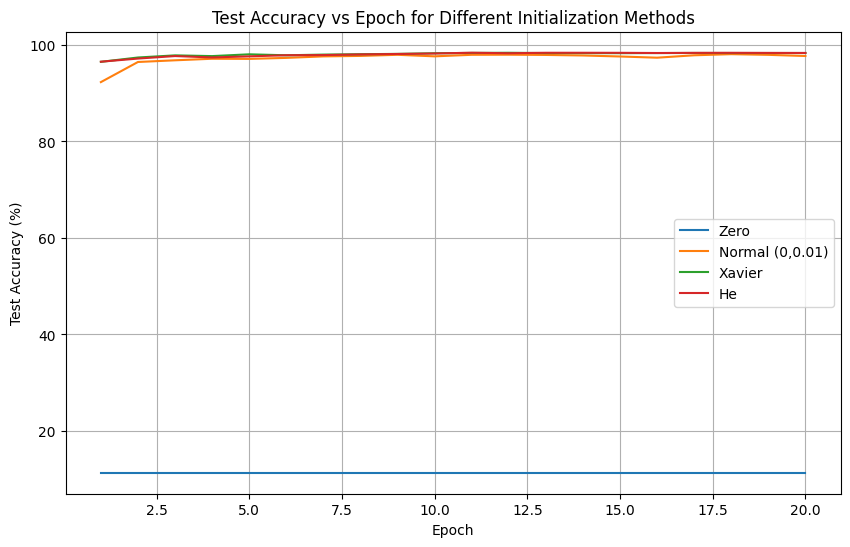


=== Epoch to reach 90% test accuracy ===
Zero                : did not reach 90% (final: 11.35%)
Normal (0,0.01)     : epoch 1
Xavier              : epoch 1
He                  : epoch 1


In [7]:

# رسم نمودار دقت آزمون
plt.figure(figsize=(10, 6))
for name, acc in results.items():
	plt.plot(range(1, len(acc)+1), acc, label=name)
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy vs Epoch for Different Initialization Methods')
plt.legend()
plt.grid(True)
plt.savefig('init_comparison.png', dpi=150)
plt.show()

# تشخیص سریع‌ترین همگرایی (رسیدن به 90%)
print("\n=== Epoch to reach 90% test accuracy ===")
for name, acc in results.items():
	for i, val in enumerate(acc):
		if val >= 90.0:
			print(f"{name:20s}: epoch {i+1}")
			break
	else:
		print(f"{name:20s}: did not reach 90% (final: {acc[-1]:.2f}%)")

3-3-2 نرﻣﺎﻝ ﺳﺎﺯﻱ ﺩﺳﺘﻪ ﺍﻱ ﺩﺭ ﺷﺒﻜﻪ ﻫﺎﻱ ﻋﻤﻴﻖ: ﻳﻚ ﺷﺒﻜﻪ ﺑﺎ ۵ ﻻﻳﻪ ﻣﺨﻔﻲ (ﻫﺮ ﻛﺪﺍﻡ ۱۲۸ ﻧﺮﻭﻥ) ﺭﻭﻱ MNIST  ﺑﺎ ﻭ ﺑﺪﻭﻥﻻﻳﻪ ﻫﺎﻱ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﺩﺳﺘﻪ ﺍﻱ ﻃﺮﺍﺣﻲ ﻛﻨﻴﺪ.

الف) ﺗﺄﺛﻴﺮ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﺩﺳﺘﻪ ﺍﻱ ﺭﺍ ﺑﺮ ﺭﻭﻱ ﭘﺎﻳﺪﺍﺭﻱ ﺁﻣﻮﺯﺵ (ﻧﻤﻮﺩﺍﺭ ﺧﻄﺎﻱ ﺁﻣﻮﺯﺵ ﺩﺭ ﻃﻮﻝ ﺩﻭﺭﻩ) ﻭ ﺩﻗﺖ ﻧﻬﺎﻳﻲ ﻣﻘﺎﻳﺴﻪ ﻛﻨﻴﺪ .

ب) ﺁﻳﺎ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﺩﺳﺘﻪ ﺍﻱ ﺍﺟﺎﺯﻩ ﻣﻲ ﺩﻫﺪ ﺍﺯ ﻧﺮﺥ ﻳﺎﺩﮔﻴﺮﻱ ﺑﺰﺭﮔﺘﺮﻱ ﺍﺳﺘﻔﺎﺩﻩ ﻛﻨﻴﺪ؟ ﻳﻚ ﺁﺯﻣﺎﻳﺶ ﺑﺎ ﻧﺮﺥ ﻳﺎﺩﮔﻴﺮﻱ 0.1 ﻭ 0.001 ﺍﻧﺠﺎﻡ ﺩﻫﻴﺪ ﻭ ﻧﺘﻴﺠﻪ ﺭﺍ ﮔﺰﺍﺭﺵ ﻛﻨﻴﺪ .

In [8]:
class DeepMLPWithoutBN(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=128, num_layers=5, num_classes=10):
        super().__init__()
        layers = []
        # لایه ورودی
        layers.append(nn.Linear(input_dim, hidden_dim))
        layers.append(nn.ReLU())
        # لایه‌های مخفی
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.ReLU())
        # لایه خروجی
        layers.append(nn.Linear(hidden_dim, num_classes))
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

class DeepMLPWithBN(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=128, num_layers=5, num_classes=10):
        super().__init__()
        layers = []
        # لایه ورودی (بدون BN در ابتدا معمول نیست، ولی می‌شود اضافه کرد)
        layers.append(nn.Linear(input_dim, hidden_dim))
        layers.append(nn.BatchNorm1d(hidden_dim))
        layers.append(nn.ReLU())
        # لایه‌های مخفی با BN
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.BatchNorm1d(hidden_dim))
            layers.append(nn.ReLU())
        # لایه خروجی
        layers.append(nn.Linear(hidden_dim, num_classes))
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)


In [9]:
def train_and_evaluate(model, trainloader, testloader, epochs=30, lr=0.01, device='cuda'):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    train_losses = []
    test_accs = []
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(trainloader)
        train_losses.append(avg_loss)
        
        # ارزیابی
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        test_acc = 100 * correct / total
        test_accs.append(test_acc)
        
        if (epoch+1) % 5 == 0:
            print(f"Epoch {epoch+1:2d} | Loss: {avg_loss:.4f} | Test Acc: {test_acc:.2f}%")
    
    return train_losses, test_accs


In [11]:
X_train, X_test, y_train, y_test, trainloader, testloader = get_mnist_data(batch_size=64)

In [12]:

device = 'cuda' if torch.cuda.is_available() else 'cpu'

learning_rates = [0.001, 0.1]
models = {
	'Without BN': DeepMLPWithoutBN,
	'With BN': DeepMLPWithBN
}

results = {}  # ساختار: (model_name, lr) -> (train_losses, test_accs)

for lr in learning_rates:
	for name, ModelClass in models.items():
		print(f"\n--- Training {name} with lr={lr} ---")
		model = ModelClass()
		losses, accs = train_and_evaluate(model, trainloader, testloader, epochs=30, lr=lr, device=device)
		results[(name, lr)] = (losses, accs)



--- Training Without BN with lr=0.001 ---
Epoch  5 | Loss: 0.2062 | Test Acc: 94.19%
Epoch 10 | Loss: 0.0923 | Test Acc: 96.34%
Epoch 15 | Loss: 0.0535 | Test Acc: 96.99%
Epoch 20 | Loss: 0.0315 | Test Acc: 97.07%
Epoch 25 | Loss: 0.0178 | Test Acc: 96.91%
Epoch 30 | Loss: 0.0097 | Test Acc: 97.25%

--- Training With BN with lr=0.001 ---
Epoch  5 | Loss: 0.0743 | Test Acc: 97.53%
Epoch 10 | Loss: 0.0359 | Test Acc: 97.87%
Epoch 15 | Loss: 0.0203 | Test Acc: 98.10%
Epoch 20 | Loss: 0.0154 | Test Acc: 98.10%
Epoch 25 | Loss: 0.0110 | Test Acc: 98.15%
Epoch 30 | Loss: 0.0075 | Test Acc: 98.17%

--- Training Without BN with lr=0.1 ---
Epoch  5 | Loss: 0.1277 | Test Acc: 96.53%
Epoch 10 | Loss: 0.1265 | Test Acc: 96.87%
Epoch 15 | Loss: nan | Test Acc: 9.80%
Epoch 20 | Loss: nan | Test Acc: 9.80%
Epoch 25 | Loss: nan | Test Acc: 9.80%
Epoch 30 | Loss: nan | Test Acc: 9.80%

--- Training With BN with lr=0.1 ---
Epoch  5 | Loss: 0.0640 | Test Acc: 97.62%
Epoch 10 | Loss: 0.0346 | Test Acc: 9

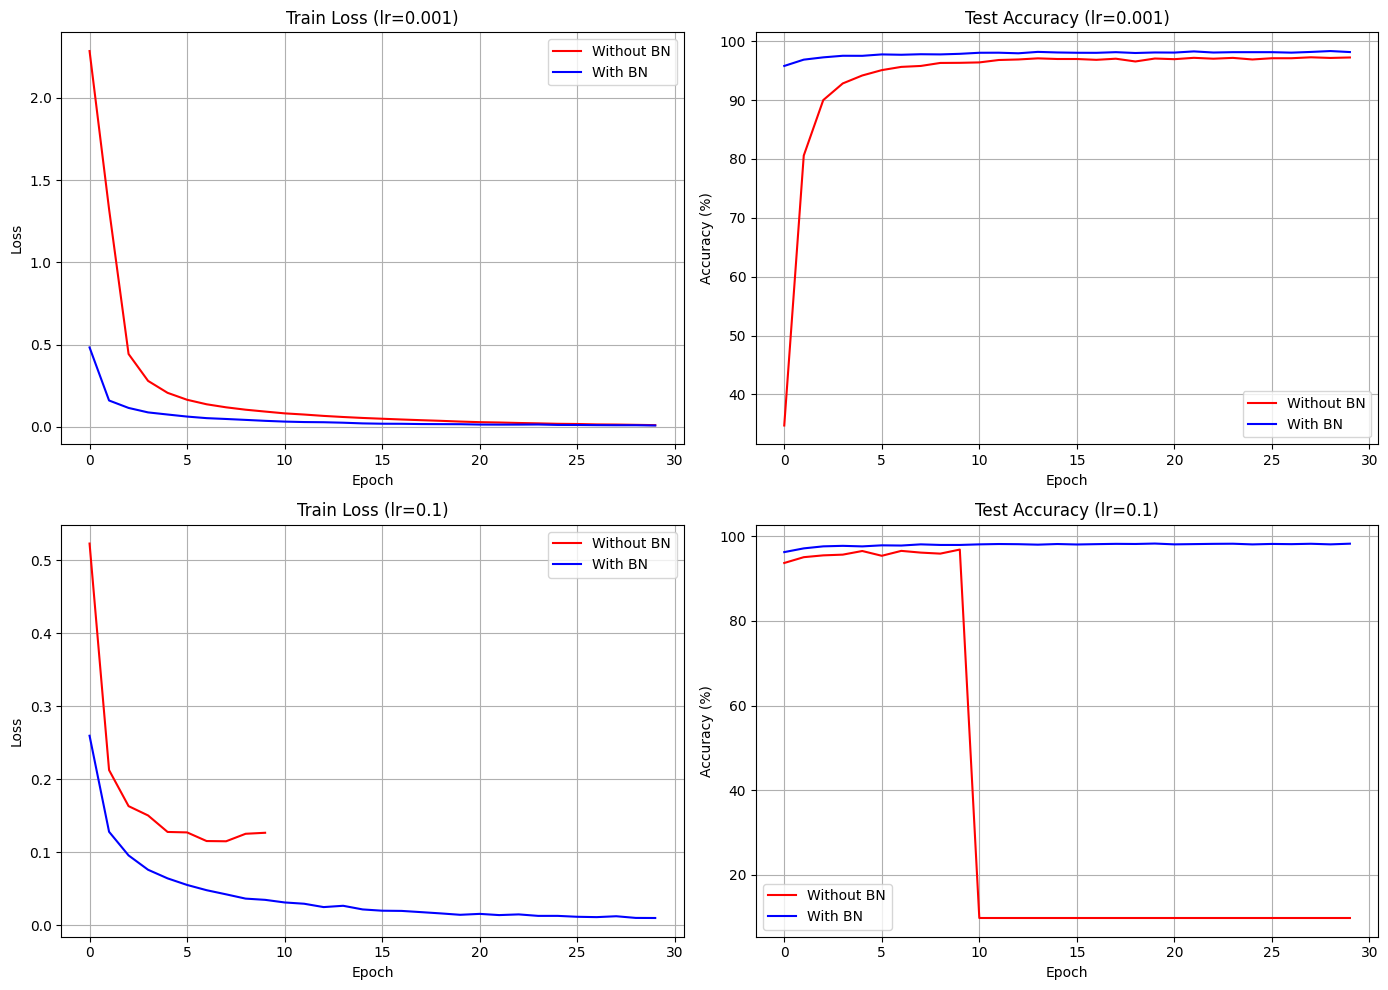


=== Final Results ===
Without BN   | lr=0.001 | Final Loss: 0.0097 | Final Acc: 97.25%
With BN      | lr=0.001 | Final Loss: 0.0075 | Final Acc: 98.17%
Without BN   | lr=  0.1 | Final Loss: nan | Final Acc: 9.80%
With BN      | lr=  0.1 | Final Loss: 0.0097 | Final Acc: 98.26%


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# برای lr=0.001
for name, color in [('Without BN', 'red'), ('With BN', 'blue')]:
	losses, accs = results[(name, 0.001)]
	axes[0,0].plot(losses, color=color, label=name)
	axes[0,1].plot(accs, color=color, label=name)
axes[0,0].set_title('Train Loss (lr=0.001)')
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('Loss')
axes[0,0].legend()
axes[0,0].grid(True)
axes[0,1].set_title('Test Accuracy (lr=0.001)')
axes[0,1].set_xlabel('Epoch')
axes[0,1].set_ylabel('Accuracy (%)')
axes[0,1].legend()
axes[0,1].grid(True)

# برای lr=0.1
for name, color in [('Without BN', 'red'), ('With BN', 'blue')]:
	losses, accs = results[(name, 0.1)]
	axes[1,0].plot(losses, color=color, label=name)
	axes[1,1].plot(accs, color=color, label=name)
axes[1,0].set_title('Train Loss (lr=0.1)')
axes[1,0].set_xlabel('Epoch')
axes[1,0].set_ylabel('Loss')
axes[1,0].legend()
axes[1,0].grid(True)
axes[1,1].set_title('Test Accuracy (lr=0.1)')
axes[1,1].set_xlabel('Epoch')
axes[1,1].set_ylabel('Accuracy (%)')
axes[1,1].legend()
axes[1,1].grid(True)

plt.tight_layout()
plt.savefig('bn_comparison.png', dpi=150)
plt.show()

# چاپ نتایج نهایی برای تحلیل
print("\n=== Final Results ===")
for (name, lr), (losses, accs) in results.items():
	print(f"{name:12s} | lr={lr:5} | Final Loss: {losses[-1]:.4f} | Final Acc: {accs[-1]:.2f}%")

3-3-3 ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﻻﻳﻪ ﺍﻱ ﺩﺭ ﻣﻘﺎﺑﻞ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﺩﺳﺘﻪ ﺍﻱ: ﺭﻭﻱ ﺩﺍﺩﻩ ﻱ moons(ﺑﺎ ﺣﺠﻢ ﻛﻢ) ﻣﻌﻤﺎﺭﻱ ﻳﻜﺴﺎﻥ ﺭﺍ ﺑﺎ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ (batchsize = 16)  ﺩﺳﺘﻪ ﺍﻱ ﻭ ﻧﺮﻣﺎﻝ ﺳﺎﺯﻱ ﻻﻳﻪ ﺍﻱ ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ. ﻛﺪﺍﻡ ﻳﻚ ﻋﻤﻠﻜﺮﺩ ﺑﻬﺘﺮﻱ ﺭﻭﻱ ﺑﺴﺘﻪ ﻫﺎﻱ ﻛﻮﭼﻚﺩﺍﺭﺩ؟ ﭼﺮﺍ؟

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_moons
from torch.utils.data import DataLoader, TensorDataset

def get_moons_small_batch(batch_size=16):
    X, y = make_moons(n_samples=400, noise=0.1, random_state=42)
    y = y.astype(np.float32)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)
    
    train_ds = TensorDataset(X_train_t, y_train_t)
    test_ds = TensorDataset(X_test_t, y_test_t)
    
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader


In [16]:
class MLPWithBatchNorm(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=64, num_layers=3):
        super().__init__()
        layers = []
        for i in range(num_layers):
            in_dim = input_dim if i == 0 else hidden_dim
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.BatchNorm1d(hidden_dim))
            layers.append(nn.ReLU())
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)

class MLPWithLayerNorm(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=64, num_layers=3):
        super().__init__()
        layers = []
        for i in range(num_layers):
            in_dim = input_dim if i == 0 else hidden_dim
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.LayerNorm(hidden_dim))
            layers.append(nn.ReLU())
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)


In [17]:
def train_and_evaluate(model, train_loader, test_loader, epochs=150, lr=0.01, device='cpu'):
    model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_accs = []
    test_accs = []
    train_losses = []
    test_losses = []
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(Xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            preds = (torch.sigmoid(out) > 0.5).float()
            correct += (preds == yb).sum().item()
            total += yb.size(0)
        train_losses.append(total_loss / len(train_loader))
        train_accs.append(100 * correct / total)
        
        model.eval()
        test_loss = 0
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                out = model(Xb)
                loss = criterion(out, yb)
                test_loss += loss.item()
                preds = (torch.sigmoid(out) > 0.5).float()
                correct_test += (preds == yb).sum().item()
                total_test += yb.size(0)
        test_losses.append(test_loss / len(test_loader))
        test_accs.append(100 * correct_test / total_test)
        
        if (epoch+1) % 30 == 0:
            print(f"Epoch {epoch+1:3d} | Train Acc: {train_accs[-1]:.2f}% | Test Acc: {test_accs[-1]:.2f}%")
    
    return train_accs, test_accs, train_losses, test_losses


In [18]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

train_loader, test_loader = get_moons_small_batch(batch_size=16)

print("\n--- Training with BatchNorm (batch_size=16) ---")
model_bn = MLPWithBatchNorm()
train_acc_bn, test_acc_bn, train_loss_bn, test_loss_bn = train_and_evaluate(
    model_bn, train_loader, test_loader, epochs=150, device=device
)

print("\n--- Training with LayerNorm (batch_size=16) ---")
model_ln = MLPWithLayerNorm()
train_acc_ln, test_acc_ln, train_loss_ln, test_loss_ln = train_and_evaluate(
    model_ln, train_loader, test_loader, epochs=150, device=device
)

Using device: cuda

--- Training with BatchNorm (batch_size=16) ---
Epoch  30 | Train Acc: 97.50% | Test Acc: 100.00%
Epoch  60 | Train Acc: 95.94% | Test Acc: 100.00%
Epoch  90 | Train Acc: 99.69% | Test Acc: 100.00%
Epoch 120 | Train Acc: 98.12% | Test Acc: 98.75%
Epoch 150 | Train Acc: 96.25% | Test Acc: 100.00%

--- Training with LayerNorm (batch_size=16) ---
Epoch  30 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch  60 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch  90 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch 120 | Train Acc: 100.00% | Test Acc: 100.00%
Epoch 150 | Train Acc: 100.00% | Test Acc: 100.00%


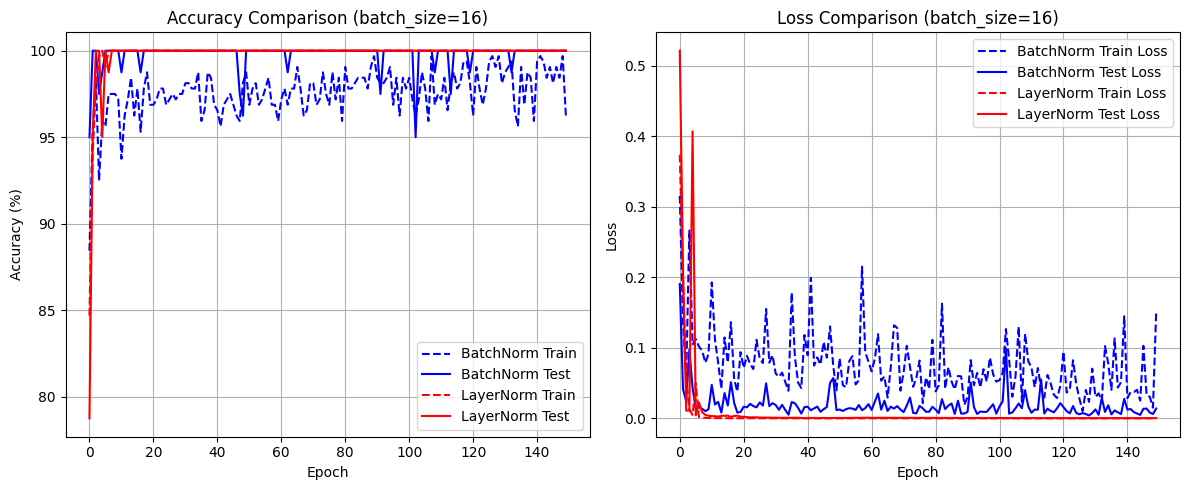


=== Final Results (batch_size=16) ===
BatchNorm  - Test Accuracy: 100.00%
LayerNorm  - Test Accuracy: 100.00%


In [19]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_acc_bn, '--', label='BatchNorm Train', color='blue')
plt.plot(test_acc_bn, '-', label='BatchNorm Test', color='blue')
plt.plot(train_acc_ln, '--', label='LayerNorm Train', color='red')
plt.plot(test_acc_ln, '-', label='LayerNorm Test', color='red')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Comparison (batch_size=16)')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(train_loss_bn, '--', label='BatchNorm Train Loss', color='blue')
plt.plot(test_loss_bn, '-', label='BatchNorm Test Loss', color='blue')
plt.plot(train_loss_ln, '--', label='LayerNorm Train Loss', color='red')
plt.plot(test_loss_ln, '-', label='LayerNorm Test Loss', color='red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Comparison (batch_size=16)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('ln_vs_bn_moons_small_batch.png', dpi=150)
plt.show()

print("\n=== Final Results (batch_size=16) ===")
print(f"BatchNorm  - Test Accuracy: {test_acc_bn[-1]:.2f}%")
print(f"LayerNorm  - Test Accuracy: {test_acc_ln[-1]:.2f}%")
